# 04. Выбор итогового разбиения, профили кластеров и их география

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import geopandas as gpd
import yaml
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import esda

from src.common import PROCESSED, RESULTS, MAPS, RAW, FEATURES, LABELS, SHORT, SEED, connected_queen
from src.viz import cluster_map, short_name, CAT, SEQ, INK, INK2, MUTED, BLUE, RED, NEUTRAL

pd.set_option("display.width", 220)
gdf = gpd.read_file(PROCESSED / "regions_digital_2021.gpkg")
lab = pd.read_csv(RESULTS / "03_labels.csv", dtype={"okato": str})
gdf = gdf.merge(lab, on=["okato", "name"], validate="one_to_one")
metrics = pd.read_csv(RESULTS / "03_partition_metrics.csv", index_col=0)
stab = pd.read_csv(RESULTS / "03_stability.csv")
w, _ = connected_queen(gdf)
METHODS = list(metrics.index)
CG = [m for m in METHODS if m.startswith("ClustGeo")][0]

E:\da-practice\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Сводное сравнение по системе показателей
Критерии сгруппированы по четырём требованиям задания: **качество** (однородность групп по признакам),
**устойчивость** (к ошибке выборочных данных и к выбору пространства признаков), **пространственные свойства**,
**интерпретируемость** (нет вырожденных кластеров; даже самые похожие типы заметно различаются по профилю). Ранги: 1 — лучший.

In [2]:
from scipy.spatial.distance import pdist
Zall = (gdf[FEATURES] - gdf[FEATURES].mean()) / gdf[FEATURES].std()

def min_centroid_gap(lab):
    """Минимальное расстояние между центрами кластеров в единицах σ: насколько различимы самые близкие типы."""
    return float(pdist(Zall.groupby(lab.to_numpy()).mean().to_numpy()).min())

summary = pd.DataFrame({
    "R2": metrics.R2, "силуэт": metrics["силуэт"],
    "ARI устойч. (σ=1)": stab[stab["σ, п. п."] == 1].groupby("метод").ARI.mean(),
    "ARI устойч. (σ=2)": stab[stab["σ, п. п."] == 2].groupby("метод").ARI.mean(),
    "фрагменты": metrics["фрагменты"], "связи внутри": metrics["связи внутри"],
    "путевой силуэт": metrics["путевой силуэт"], "мин. размер": metrics["мин. размер"],
    "мин. разрыв центров, σ": pd.Series({m: min_centroid_gap(gdf[m]) for m in metrics.index}),
}).loc[METHODS]
higher = ["R2", "силуэт", "ARI устойч. (σ=1)", "ARI устойч. (σ=2)", "связи внутри", "путевой силуэт", "мин. размер", "мин. разрыв центров, σ"]
ranks = pd.DataFrame({c: summary[c].rank(ascending=c not in higher) for c in summary})
groups = {"качество": ["R2", "силуэт"], "устойчивость": ["ARI устойч. (σ=1)", "ARI устойч. (σ=2)"],
          "пространство": ["фрагменты", "связи внутри", "путевой силуэт"], "интерпретируемость": ["мин. размер", "мин. разрыв центров, σ"]}
grank = pd.DataFrame({g: ranks[c].mean(axis=1) for g, c in groups.items()})
grank["средний ранг"] = grank.mean(axis=1)
summary.to_csv(RESULTS / "04_summary_metrics.csv", encoding="utf-8")
grank.to_csv(RESULTS / "04_group_ranks.csv", encoding="utf-8")
display(summary.round(3)); grank.round(2).sort_values("средний ранг")

,R2,силуэт,ARI устойч. (σ=1),ARI устойч. (σ=2),фрагменты,связи внутри,путевой силуэт,мин. размер,"мин. разрыв центров, σ"
k-средних,0.783,0.322,0.858,0.669,36,0.307,-0.098,7,1.482
ClustGeo α=0.25,0.616,0.016,0.742,0.648,16,0.604,0.153,9,0.584
Уорд со смежностью,0.381,0.109,0.762,0.667,5,0.875,0.075,2,0.642
SKATER,0.322,-0.049,0.752,0.694,5,0.839,0.266,3,0.642
Max-p,0.385,-0.121,0.551,0.540,8,0.510,0.108,5,0.180


,качество,устойчивость,пространство,интерпретируемость,средний ранг
k-средних,1.0,1.5,5.00,1.50,2.25
SKATER,4.5,2.0,1.50,3.25,2.81
Уорд со смежностью,3.0,2.5,2.17,3.75,2.85
ClustGeo α=0.25,2.5,4.0,3.00,2.50,3.00
Max-p,4.0,5.0,3.33,4.00,4.08


**Выбор.** Цель исследования — выделить группы регионов со сходным уровнем цифрового развития и затем
изучить их географию, то есть сначала **типология**, потом её пространственный анализ.

- Методы с жёсткой связностью (Уорд со смежностью, SKATER, Max-p) объясняют лишь 32–39 % дисперсии против
  78 % у k-средних, силуэт у них около нуля или отрицателен: «цена» требования связности — больше половины
  однородности. Это прямое следствие диагностики: пространственная автокорреляция показателей умеренная
  (I ≈ 0,17–0,28), сплошных макрозон цифрового развития нет. Кроме того, Уорд со смежностью даёт вырожденные
  кластеры (2–3 региона рядом с крупным кластером из 62), а SKATER и Уорд неустойчивы (минимальный ARI 0,05–0,18).
- **k-средних** лучший по качеству, устойчивости (средний ARI 0,86 при σ = 1 п. п.) и нечувствителен к
  переходу в пространство главных компонент (ARI 0,98); недостаток — мозаичность (36 фрагментов).
- **ClustGeo (α = 0,25)** — компромисс: вдвое больше связей внутри кластеров (0,60 против 0,31), вдвое меньше
  фрагментов (16 против 36), но $R^2$ ниже (0,62) и силуэт ≈ 0: группы сильнее перекрываются в пространстве признаков.

**Итоговое решение — разбиение k-средних (k = 5)** как наиболее однородная, устойчивая и интерпретируемая
типология. ClustGeo (α = 0,25) используется как дополнительная «территориальная» версия для карт и
региональной политики: она показывает, какие типы складываются в связные зоны, а какие остаются
точечными. Отсутствие связных макрозон — содержательный результат, а не недостаток решения.

In [3]:
FINAL = "k-средних"
gdf["cluster"] = gdf[FINAL]
prof = gdf.groupby("cluster")[FEATURES].mean()
prof_z = (prof - gdf[FEATURES].mean()) / gdf[FEATURES].std()
prof.assign(n=gdf.cluster.value_counts().sort_index(),
            население_млн=gdf.groupby("cluster").pop_thousands.sum() / 1000).round(1)

,pc,internet,broadband,daily_users,n,население_млн
cluster,,,,,,
1,61.7,76.0,73.6,73.3,18,18.4
2,68.2,80.6,79.5,77.2,32,54.9
3,65.6,88.9,86.9,85.3,15,16.3
4,80.3,87.3,86.0,82.7,13,37.5
5,87.2,95.4,94.5,91.0,7,18.5


## 2. Содержательная интерпретация кластеров
Названия даны по профилю средних (номер растёт с общим уровнем цифровизации, PC1).

In [4]:
NAMES = {
    1: "1 · Отстающие",
    2: "2 · Средний уровень",
    3: "3 · Мобильная модель (интернет без ПК)",
    4: "4 · Развитые",
    5: "5 · Лидеры",
}
gdf["cluster_name"] = gdf.cluster.map(NAMES)
for c, d in gdf.groupby("cluster"):
    print(NAMES[c], f"({len(d)}):", ", ".join(short_name(n) for n in d.name.sort_values()))

1 · Отстающие (18): Еврейская АО, Забайкальский кр., Ивановская, Кировская, Костромская, Красноярский кр., Курганская, Липецкая, Новгородская, Орловская, Марий Эл, Мордовия, Хакасия, Рязанская, Тверская, Тюменская*, Ульяновская, Ярославская
2 · Средний уровень (32): Алтайский кр., Архангельская*, Белгородская, Брянская, Владимирская, Вологодская, Иркутская, Калужская, Кемеровская, Курская, Ленинградская, Ненецкий АО, Нижегородская, Пензенская, Пермский кр., Псковская, Алтай, Башкортостан, Ингушетия, Карелия, Коми, Ростовская, Самарская, Саратовская, Свердловская, Смоленская, Ставропольский кр., Тамбовская, Томская, Удмуртская, Хабаровский кр., Чувашская
3 · Мобильная модель (интернет без ПК) (15): Амурская, Кабардино-Балкарская, Камчатский кр., Карачаево-Черкесская, Новосибирская, Омская, Приморский кр., Адыгея, Бурятия, Дагестан, Калмыкия, Саха (Якутия), Сев. Осетия, Тыва, Сахалинская
4 · Развитые (13): Астраханская, Волгоградская, Воронежская, Калининградская, Краснодарский кр., Моск

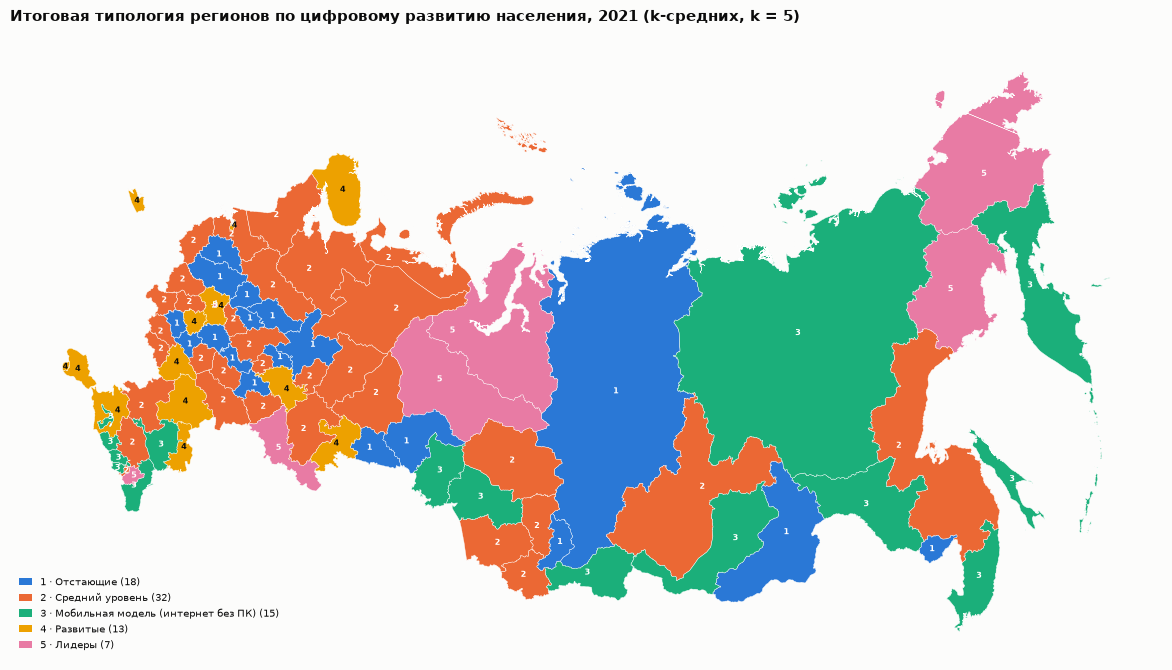

In [5]:
fig, ax = plt.subplots(figsize=(16, 8))
cluster_map(ax, gdf, gdf.cluster.to_numpy(), names=NAMES,
            title="Итоговая типология регионов по цифровому развитию населения, 2021 (k-средних, k = 5)")
plt.savefig(MAPS / "04_final_clusters.png", dpi=170, bbox_inches="tight"); plt.show()

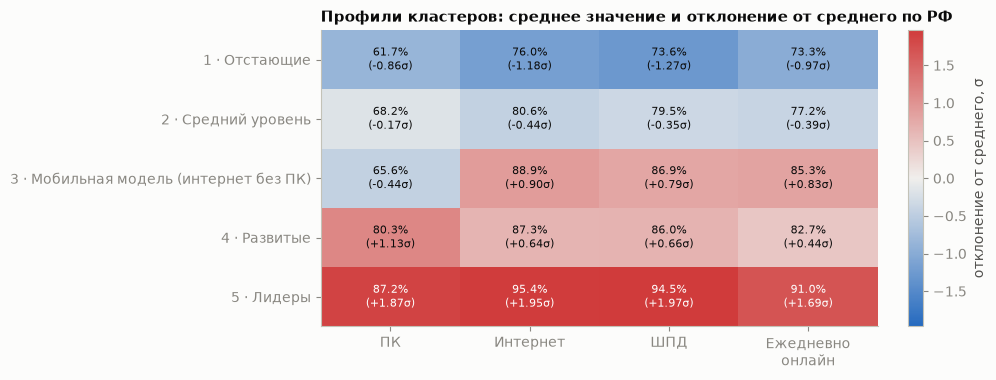

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.9))
v = prof_z.to_numpy()
lim = np.abs(v).max()
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", [BLUE, NEUTRAL, RED])
im = ax.imshow(v, cmap=div, vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
ax.set_xticks(range(4), ["ПК", "Интернет", "ШПД", "Ежедневно\nонлайн"]); ax.set_yticks(range(len(NAMES)), [NAMES[c] for c in prof_z.index])
for i in range(v.shape[0]):
    for j in range(v.shape[1]):
        ax.text(j, i, f"{prof.iloc[i, j]:.1f}%\n({v[i, j]:+.2f}σ)", ha="center", va="center", fontsize=8,
                color="#ffffff" if abs(v[i, j]) > 0.65 * lim else INK)
plt.colorbar(im, ax=ax, fraction=0.04, label="отклонение от среднего, σ")
ax.set_title("Профили кластеров: среднее значение и отклонение от среднего по РФ", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "04_cluster_profiles.png", dpi=150, bbox_inches="tight"); plt.show()

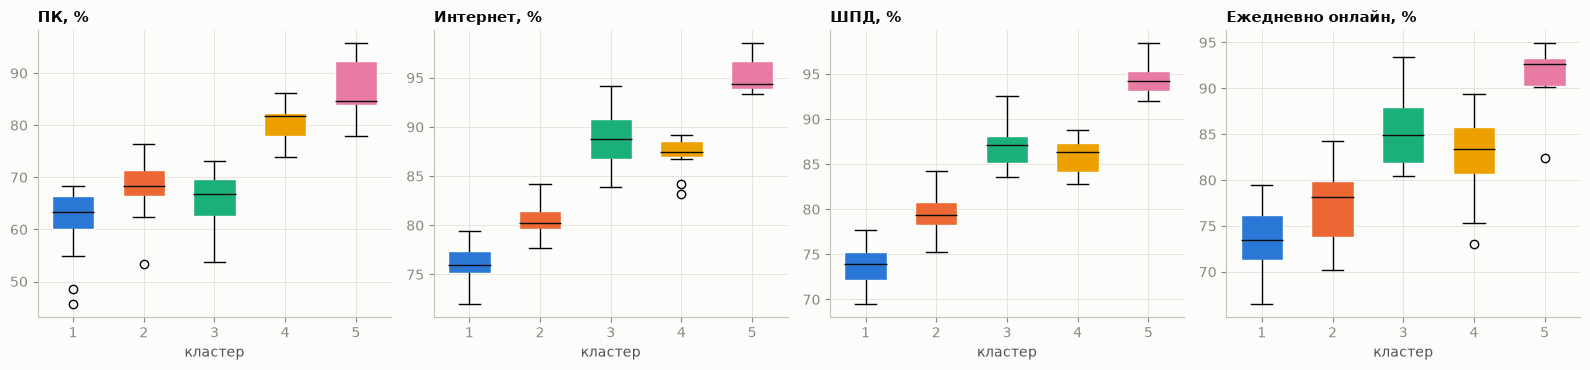

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, f in zip(axes, FEATURES):
    data = [gdf.loc[gdf.cluster == c, f] for c in NAMES]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops=dict(color=INK))
    for b, c in zip(bp["boxes"], CAT):
        b.set_facecolor(c); b.set_edgecolor("#ffffff")
    ax.set_xticks(range(1, 6), list(NAMES)); ax.set_xlabel("кластер"); ax.set_title(SHORT[f] + ", %", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "04_cluster_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. География кластеров
### 3.1. Распределение по федеральным округам
Принадлежность к федеральному округу — из эталонного справочника регионов (поле `parent_name`).

In [8]:
etalon = yaml.safe_load(open(RAW / "_source" / "regions_etalon.yaml", encoding="utf-8"))["dict"]
by_name = {v["name_rus"]: v for v in etalon.values()}
def fed_district(v):
    # у «области без АО» родитель — сама область; поднимаемся по иерархии до федерального округа
    while v is not None and not str(v["parent_name"]).endswith("федеральный округ"):
        v = by_name.get(v["parent_name"])
    return None if v is None else v["parent_name"]
okato_fd = {v["okato"]: fed_district(v) for v in etalon.values() if v["level"] == "регион"}
name_fd = {v["name_rst_data"]: fed_district(v) for v in etalon.values() if v["level"] == "регион"}
gdf["fd"] = gdf.okato.map(okato_fd).fillna(gdf.name.map(name_fd)).str.replace(" федеральный округ", "")
print("без ФО:", gdf.loc[gdf.fd.isna(), "name"].tolist())
ct = pd.crosstab(gdf.fd, gdf.cluster_name)
ct.to_csv(RESULTS / "04_clusters_by_federal_district.csv", encoding="utf-8")
ct

без ФО: []


cluster_name,1 · Отстающие,2 · Средний уровень,3 · Мобильная модель (интернет без ПК),4 · Развитые,5 · Лидеры
fd,,,,,
Дальневосточный,2,1,6,0,2
Приволжский,4,8,0,1,1
Северо-Западный,1,7,0,3,0
Северо-Кавказский,0,2,4,0,1
Сибирский,2,5,3,0,0
Уральский,2,1,0,1,2
Центральный,7,7,0,3,1
Южный,0,1,2,5,0


### 3.2. Пространственная автокорреляция меток кластеров
Для каждого кластера — тест числа соединений (join count): сколько пар соседних регионов **оба** входят
в кластер (BB) по сравнению с ожидаемым при случайном размещении меток (9 999 перестановок). Значимое
превышение — кластер образует территориальное сгущение; незначимое — регионы типа разбросаны по стране.

In [9]:
jc_rows = []
w_b = connected_queen(gdf)[0]; w_b.transform = "b"
for c in NAMES:
    y = (gdf.cluster == c).astype(int).to_numpy()
    jc = esda.Join_Counts(y, w_b, permutations=9999)
    jc_rows.append({"кластер": NAMES[c], "регионов": int(y.sum()), "BB набл.": jc.bb, "BB ожид.": jc.mean_bb,
                    "p (BB)": jc.p_sim_bb})
jc_tab = pd.DataFrame(jc_rows).set_index("кластер")
jc_tab.to_csv(RESULTS / "04_join_counts.csv", encoding="utf-8")
jc_tab.round(3)

,регионов,BB набл.,BB ожид.,p (BB)
кластер,,,,
1 · Отстающие,18,13.0,8.243,0.065
2 · Средний уровень,32,33.0,26.760,0.104
3 · Мобильная модель (интернет без ПК),15,6.0,5.634,0.492
4 · Развитые,13,5.0,4.223,0.403
5 · Лидеры,7,2.0,1.132,0.302


### 3.3. Итоговое разбиение и его территориальная версия
Слева — итоговая типология (k-средних), справа — ClustGeo (α = 0,25). Регионы, сменившие тип при учёте
географии, — это «выбивающиеся» из своего окружения регионы: их показатели ближе к другому типу,
чем у соседей.

совпадают 53 из 85 регионов; сменили тип:
                               name  k-средних  ClustGeo
                     Алтайский край          2         1
                   Хабаровский край          2         3
                 Ивановская область          1         2
                  Иркутская область          2         3
               Республика Ингушетия          2         4
            Калининградская область          4         5
                   Тверская область          1         2
                Кемеровская область          2         1
                  Кировская область          1         2
                Костромская область          1         2
                 г. Санкт-Петербург          4         5
                   Липецкая область          1         2
                 Московская область          4         5
                 Мурманская область          4         5
               Новгородская область          1         2
               Оренбургская область          5

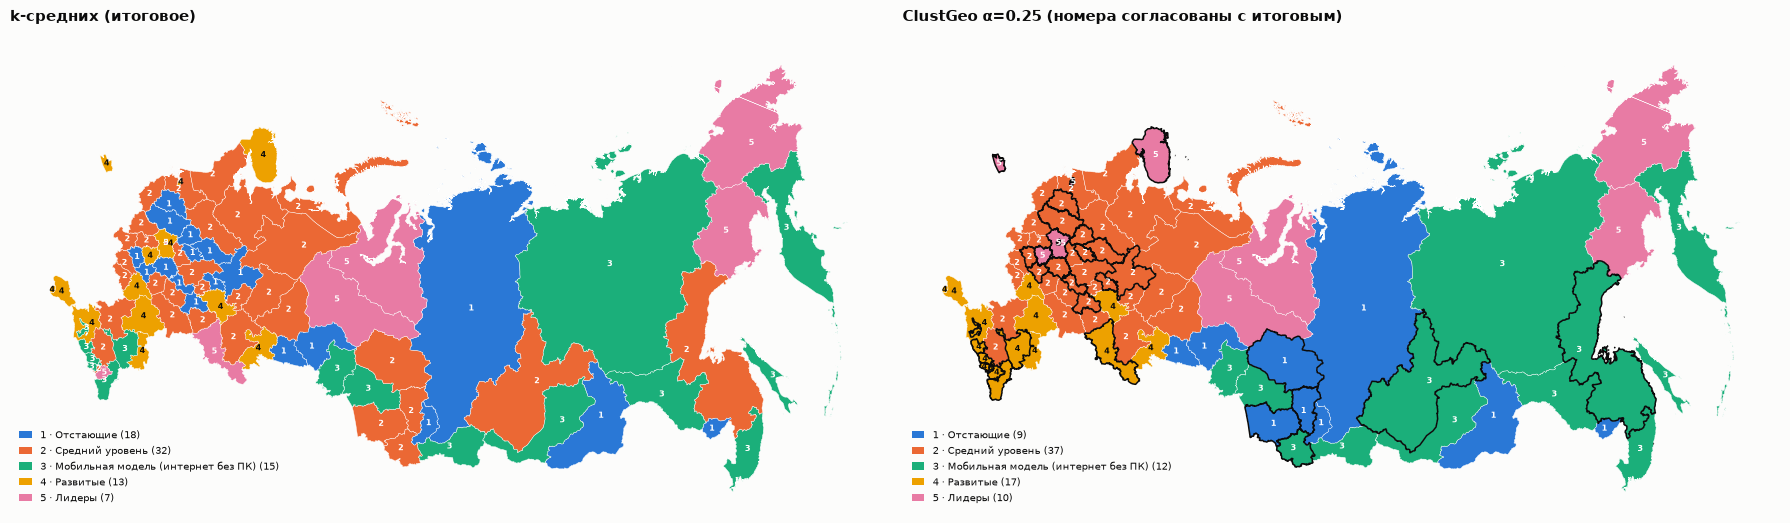

In [10]:
from scipy.optimize import linear_sum_assignment
cm = pd.crosstab(gdf[FINAL], gdf[CG])
r, c = linear_sum_assignment(-cm.to_numpy())
mapping = {cm.columns[j]: cm.index[i] for i, j in zip(r, c)}
gdf["cg_aligned"] = gdf[CG].map(mapping)
changed = gdf[gdf.cg_aligned != gdf.cluster]
print(f"совпадают {int((gdf.cg_aligned == gdf.cluster).sum())} из 85 регионов; сменили тип:")
print(changed[["name", "cluster", "cg_aligned"]].rename(columns={"cluster": "k-средних", "cg_aligned": "ClustGeo"}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(18, 6.2))
cluster_map(axes[0], gdf, gdf.cluster.to_numpy(), names=NAMES, title="k-средних (итоговое)")
cluster_map(axes[1], gdf, gdf.cg_aligned.to_numpy(), names=NAMES, title=f"{CG} (номера согласованы с итоговым)")
gdf[gdf.cg_aligned != gdf.cluster].boundary.plot(ax=axes[1], color=INK, linewidth=1.1)
plt.tight_layout(); plt.savefig(MAPS / "04_final_vs_clustgeo.png", dpi=150, bbox_inches="tight"); plt.show()

### 3.4. Типичные и пограничные регионы
Силуэт отдельного региона показывает, насколько уверенно он отнесён к своему кластеру: значения около нуля
и отрицательные — пограничные регионы между двумя типами.

In [11]:
from sklearn.metrics import silhouette_samples
from sklearn.preprocessing import StandardScaler
Zs = StandardScaler().fit_transform(gdf[FEATURES])
gdf["silhouette_i"] = silhouette_samples(Zs, gdf.cluster)
print("доля регионов с отрицательным силуэтом:", round((gdf.silhouette_i < 0).mean(), 3))
gdf.sort_values("silhouette_i")[["name", "cluster_name", "silhouette_i"]].head(8).round(3)

доля регионов с отрицательным силуэтом: 0.024


,name,cluster_name,silhouette_i
39,Новосибирская область,3 · Мобильная модель (интернет без ПК),-0.059
41,Оренбургская область,5 · Лидеры,-0.023
23,Камчатский край,3 · Мобильная модель (интернет без ПК),0.003
2,Красноярский край,1 · Отстающие,0.062
29,Курганская область,1 · Отстающие,0.076
1,Краснодарский край,4 · Развитые,0.080
70,Республика Калмыкия,3 · Мобильная модель (интернет без ПК),0.081
27,Республика Крым,4 · Развитые,0.093


In [12]:
cols = ["okato", "name", "fd", *FEATURES, "pop_thousands", "cluster", "cluster_name", "cg_aligned", "silhouette_i"]
gdf[cols].to_csv(RESULTS / "04_final_classification.csv", index=False, encoding="utf-8")
gdf[[*cols, "geometry"]].to_file(RESULTS / "04_final_classification.gpkg", driver="GPKG")